# GQA Stage 1 — dữ liệu và đề xuất quy tắc

Notebook này là ảnh chụp kết quả Stage 1. Bảng và biểu đồ đã được lưu sẵn để xem mà không cần chạy lại. Ba tệp cấu hình vẫn ở trạng thái **PROPOSED**; chưa có tác vụ nào được cố định.

Source commit: `c091fd75c7125ea98475fd5592170e8b391cf7e4`. Đầu vào và phiên bản thư viện nằm trong `gqa_audit/outputs/stage1/run_manifest.json`.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path(globals().get('_AUDIT_ROOT', Path.cwd()))
if not (ROOT / 'gqa_audit').exists(): ROOT = ROOT.parent
OUT = ROOT / 'gqa_audit' / 'outputs' / 'stage1'
inventory = pd.read_csv(OUT / 'detailed_type_inventory.csv')
operations = pd.read_csv(OUT / 'operation_catalogue.csv')
candidates = pd.read_csv(OUT / 'candidate_counts.csv')


## Quy mô ba split


In [2]:
sizes = inventory.groupby('split', as_index=False)['count'].sum()
print(sizes.to_string(index=False))


  split  count
testdev  12578
  train 943000
    val 132062


## Phân bố `types.detailed`


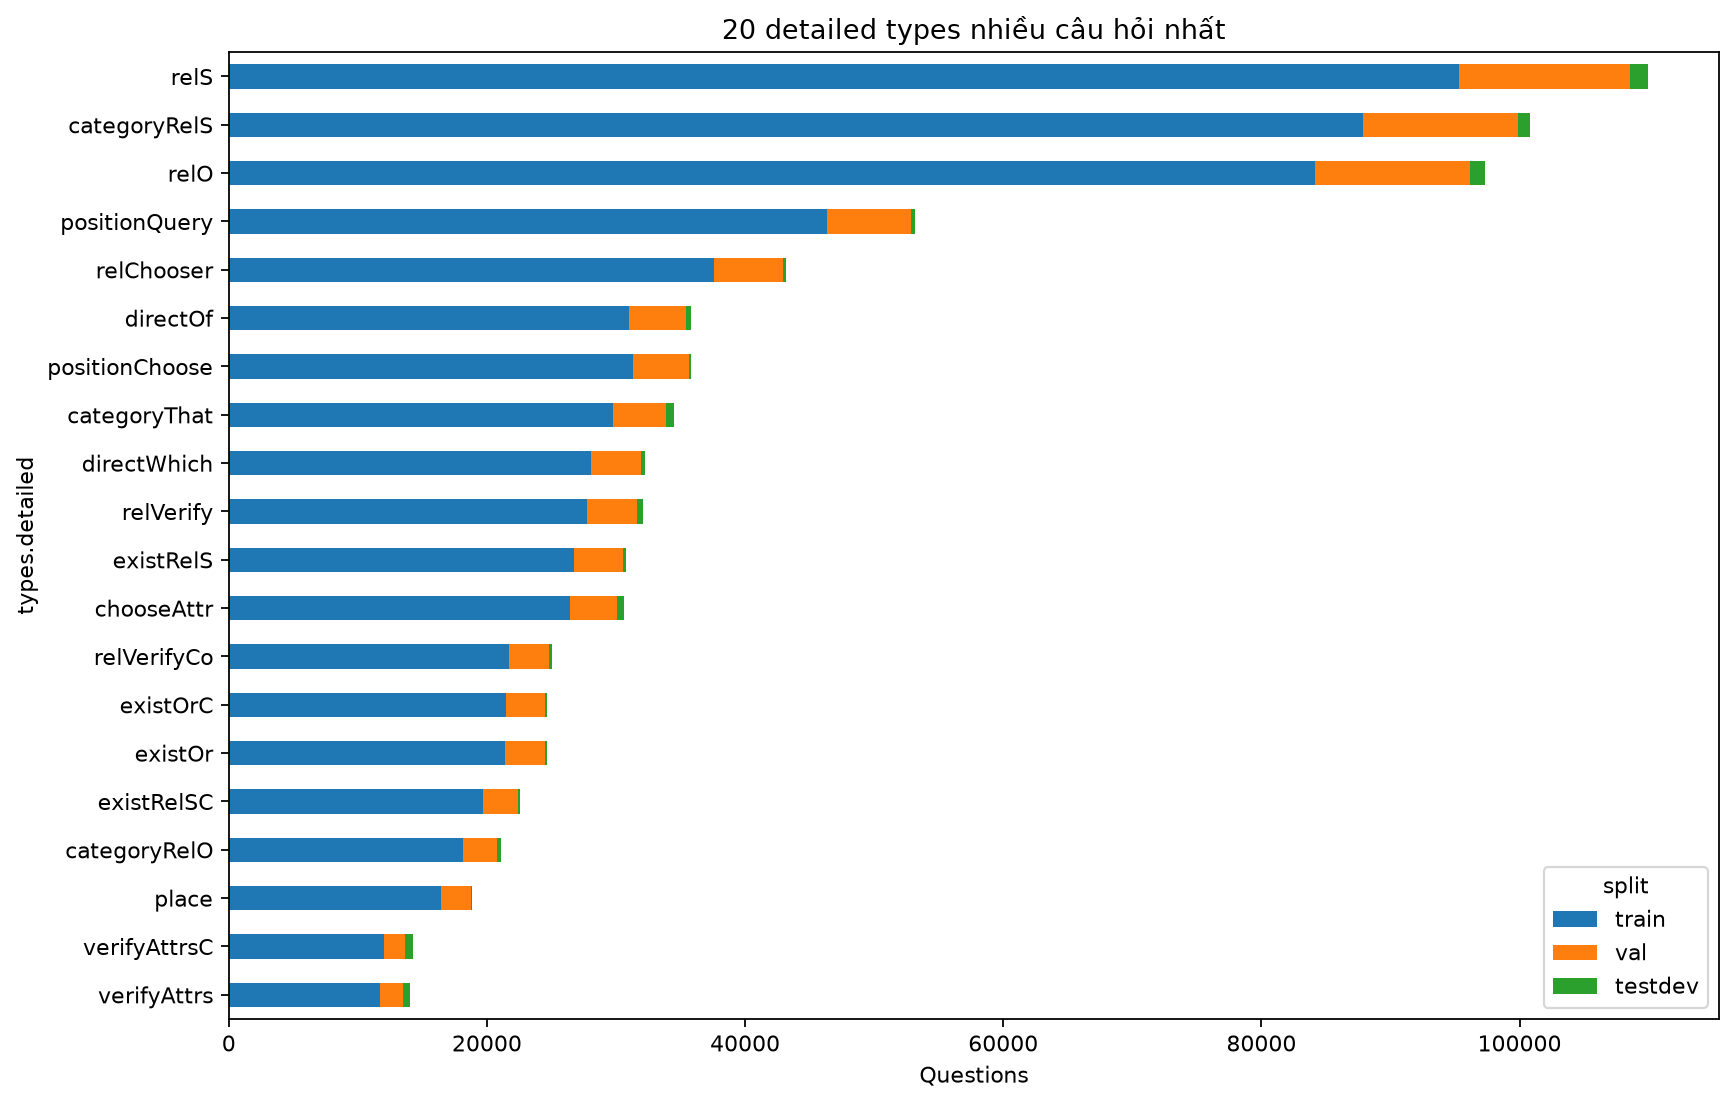

In [3]:
top = inventory.groupby('types_detailed')['count'].sum().nlargest(20).index
pivot = inventory[inventory.types_detailed.isin(top)].pivot_table(
    index='types_detailed', columns='split', values='count', aggfunc='sum', fill_value=0
).reindex(top).reindex(columns=['train', 'val', 'testdev'], fill_value=0)
ax = pivot.iloc[::-1].plot.barh(stacked=True, figsize=(11, 7), title='20 detailed types nhiều câu hỏi nhất')
ax.set(xlabel='Questions', ylabel='types.detailed')
plt.tight_layout(); plt.show()


## Thành phần đáp án theo loại câu hỏi


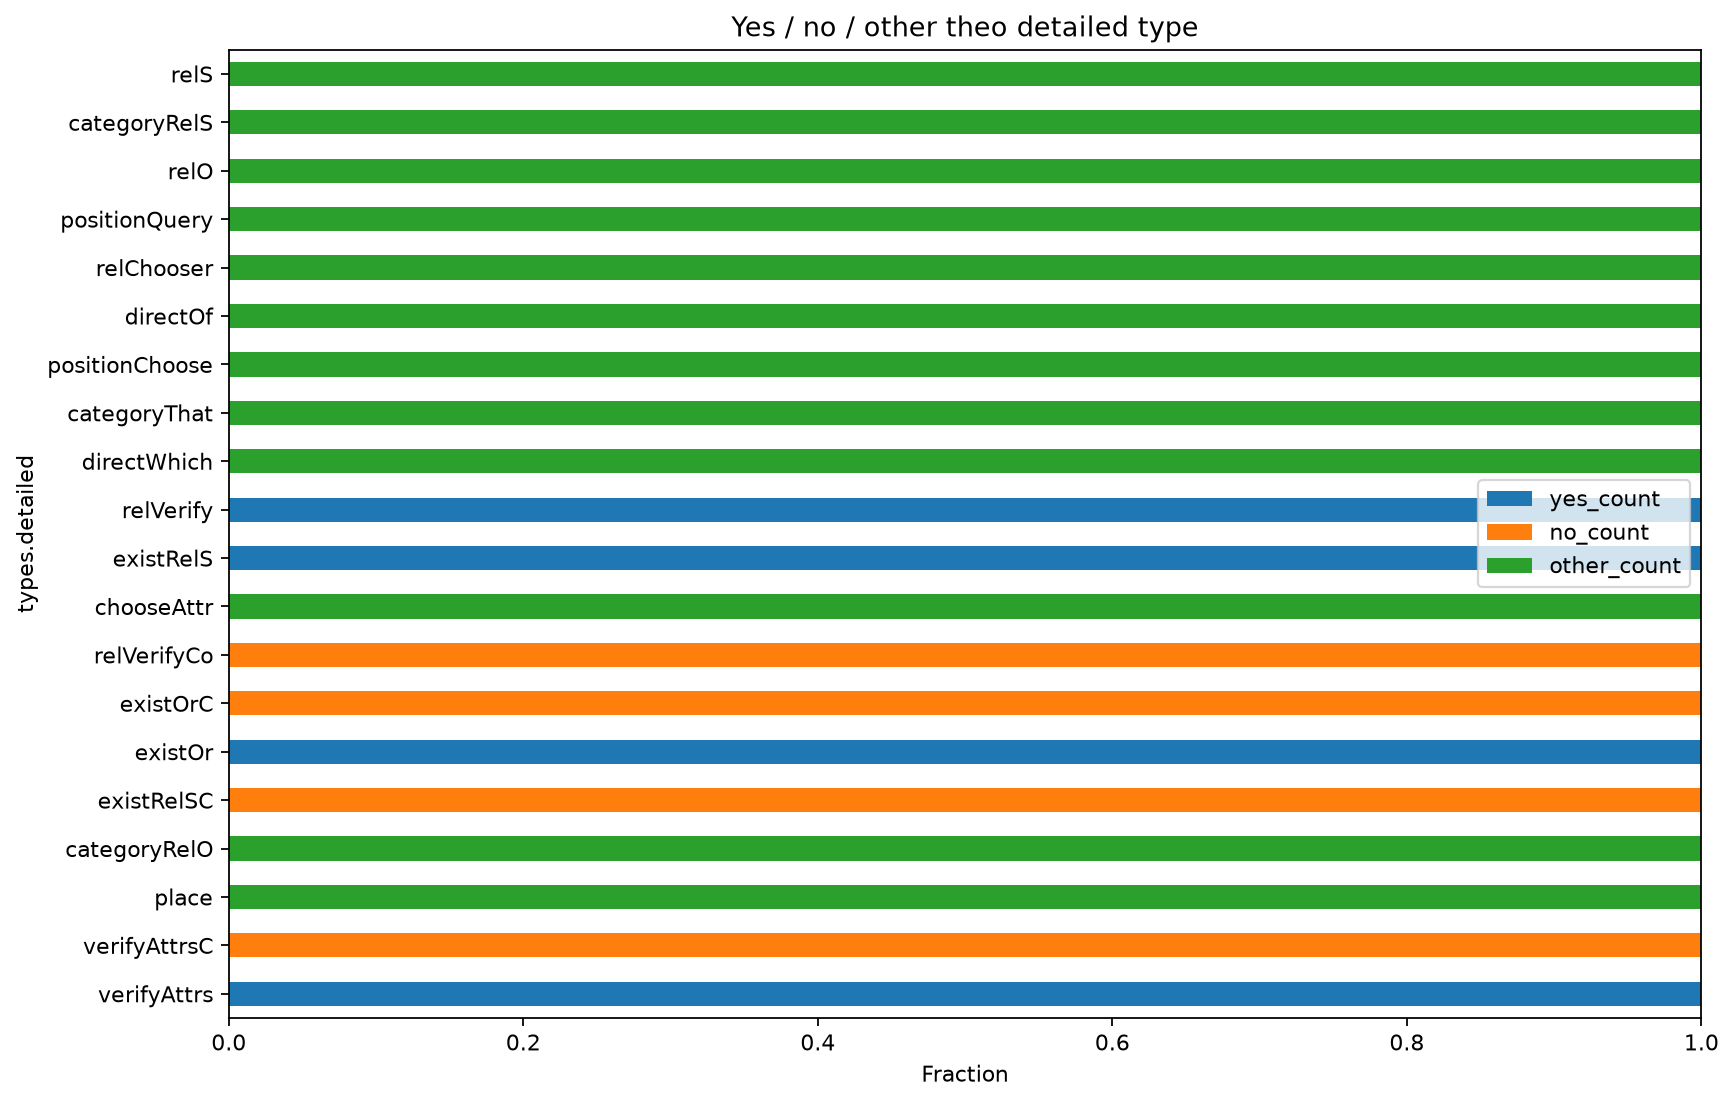

In [4]:
answers = inventory.groupby('types_detailed')[['yes_count', 'no_count', 'other_count']].sum().loc[top]
fractions = answers.div(answers.sum(axis=1), axis=0)
ax = fractions.iloc[::-1].plot.barh(stacked=True, figsize=(11, 7), title='Yes / no / other theo detailed type')
ax.set(xlabel='Fraction', ylabel='types.detailed', xlim=(0, 1))
plt.tight_layout(); plt.show()


## Các thao tác trong chương trình suy luận


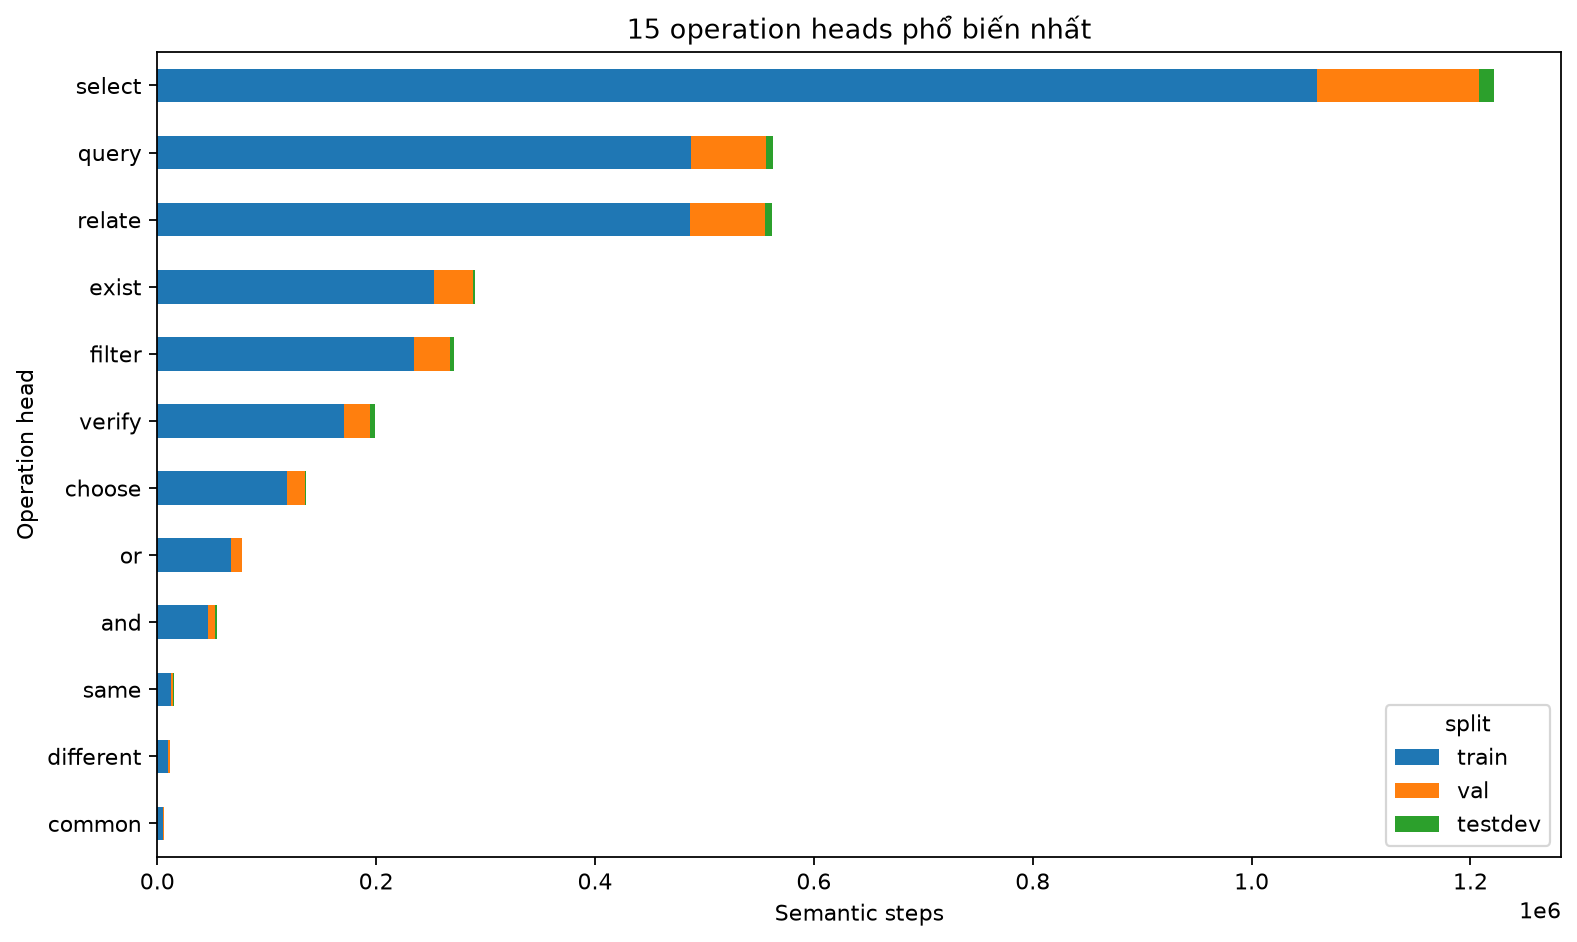

In [5]:
head_counts = operations.drop_duplicates(['split', 'head'])
head_top = head_counts.groupby('head')['head_count'].sum().nlargest(15).index
head_pivot = head_counts[head_counts['head'].isin(head_top)].pivot_table(
    index='head', columns='split', values='head_count', aggfunc='sum', fill_value=0
).reindex(head_top).reindex(columns=['train', 'val', 'testdev'], fill_value=0)
ax = head_pivot.iloc[::-1].plot.barh(stacked=True, figsize=(10, 6), title='15 operation heads phổ biến nhất')
ax.set(xlabel='Semantic steps', ylabel='Operation head')
plt.tight_layout(); plt.show()


## Ảnh hưởng của bộ lọc relation

Mẫu số là câu hỏi yes/no có chương trình không rỗng trong các nhóm dự kiến. Các con số này chỉ hỗ trợ duyệt quy tắc; chưa chọn định nghĩa chính thức.


In [6]:
impact = candidates.groupby('task')[['eligible_yesno_nonempty', 'R_strict_removed', 'R_broad_removed']].sum()
impact = impact.loc[[task for task in ['exist', 'verifyAttr', 'compare'] if task in impact.index]]
print(impact.to_string())


            eligible_yesno_nonempty  R_strict_removed  R_broad_removed
task                                                                  
exist                         85930             61885            61885
verifyAttr                    40605             10216            10216
compare                       22764                 0                0


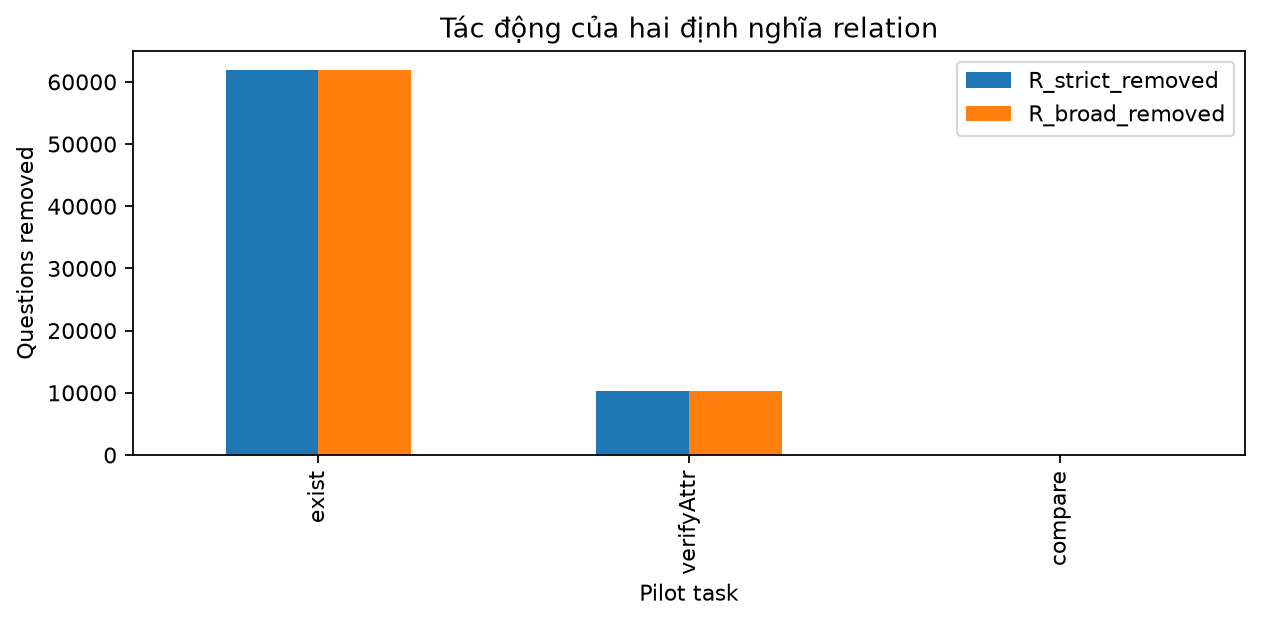

In [7]:
ax = impact[['R_strict_removed', 'R_broad_removed']].plot.bar(figsize=(8, 4), title='Tác động của hai định nghĩa relation')
ax.set(xlabel='Pilot task', ylabel='Questions removed')
plt.tight_layout(); plt.show()


## Kiểm tra eligibility sau khi sửa lỗi YAML

PyYAML từng đọc yes/no không có dấu nháy thành boolean. Lần chạy này dùng chuỗi đã kiểm tra kiểu; số eligible được đối chiếu với bộ đếm đáp án và chương trình rỗng theo từng detailed type.


In [8]:
checks = pd.read_csv(OUT / 'validation_checks.csv')
print(checks.groupby('status').size().to_string())
print(candidates.groupby(['task', 'split'])[['raw_count', 'eligible', 'n_empty_program']].sum().to_string())


status
PASS    336
                    raw_count  eligible  n_empty_program
task       split                                        
compare    testdev        444       444                0
           train        19548     19548                0
           val           2772      2772                0
exist      testdev        556       556                0
           train        74826     74826                0
           val          10548     10548                0
logic      testdev       1803      1803                0
           train       114029    114029                0
           val          16096     16096                0
verifyAttr testdev        712       712                0
           train        34979     34979                0
           val           4914      4914                0
verifyRel  testdev        769       769                0
           train        56523     56523                0
           val           7933      7933                0


## Quy mô tác vụ theo biến thể đề xuất (train)


             variant       task  questions  yes_ratio  exclusion_rate
          unfiltered      exist      74826   0.497113        0.000000
          unfiltered verifyAttr      34979   0.494468        0.000000
          unfiltered  verifyRel      56523   0.491428        0.000000
          unfiltered    compare      19548   0.489820        0.000000
          unfiltered      logic     114029   0.506564        0.000000
      program_strict      exist      21004   0.499238        0.719295
      program_strict verifyAttr      26183   0.494061        0.251465
      program_strict  verifyRel      56523   0.491428        0.000000
      program_strict    compare      19548   0.489820        0.000000
      program_strict      logic     114029   0.506564        0.000000
       program_broad      exist      21004   0.499238        0.719295
       program_broad verifyAttr      26183   0.494061        0.251465
       program_broad  verifyRel      56523   0.491428        0.000000
       program_broad

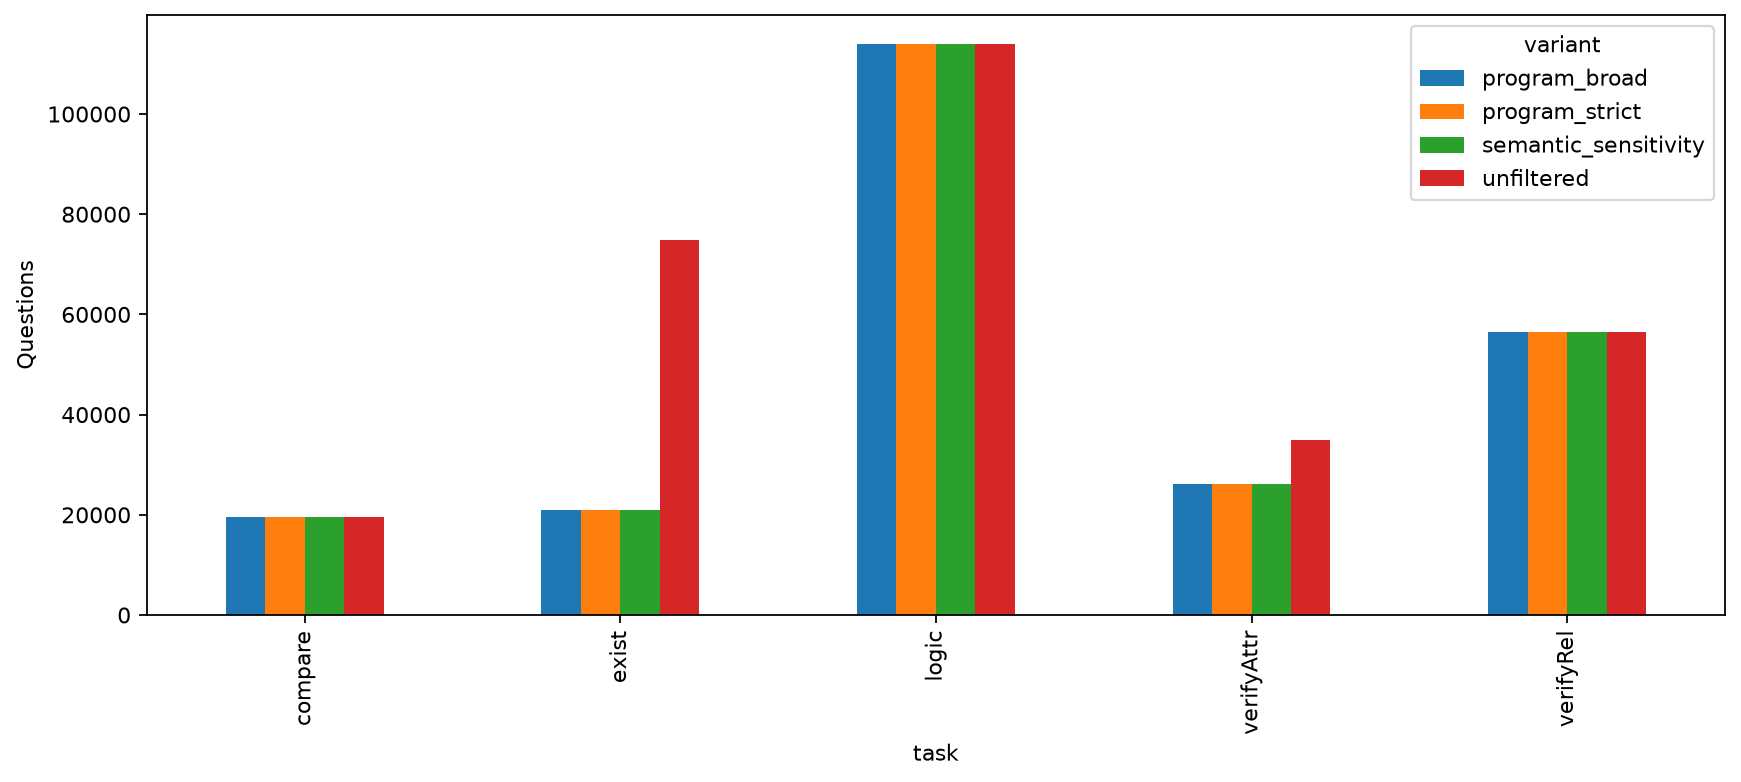

In [9]:
variants = pd.read_csv(OUT / 'variant_counts.csv')
task_train = variants[(variants['level'] == 'task') & (variants['split'] == 'train')]
print(task_train[['variant', 'task', 'questions', 'yes_ratio', 'exclusion_rate']].to_string(index=False))
task_train.pivot(index='task', columns='variant', values='questions').plot.bar(figsize=(11, 5))
plt.ylabel('Questions'); plt.tight_layout(); plt.show()


## Cân bằng đáp án theo family (train, unfiltered)

Family chỉ phục vụ kiểm toán. Các family một lớp được báo cờ; không có bước tái cân bằng tự động.


                         task  questions    yes     no          flag
family                                                              
exist                   exist      11285   5564   5721           NaN
existAnd                logic      21436  10683  10753           NaN
existAttr               exist       2828   1410   1418           NaN
existAttrNot            exist       2953   1513   1440           NaN
existAttrOr             logic      16336   8378   7958           NaN
existMaterial           exist        344    179    165           NaN
existMaterialNot        exist        399    210    189           NaN
existOr                 logic      42916  21405  21511           NaN
existRelS               exist      53822  26711  27111           NaN
existThat               exist       2922   1482   1440           NaN
existThatNot            exist        273    128    145           NaN
existThatOr             logic       8299   4254   4045           NaN
relVerify           verifyRel     

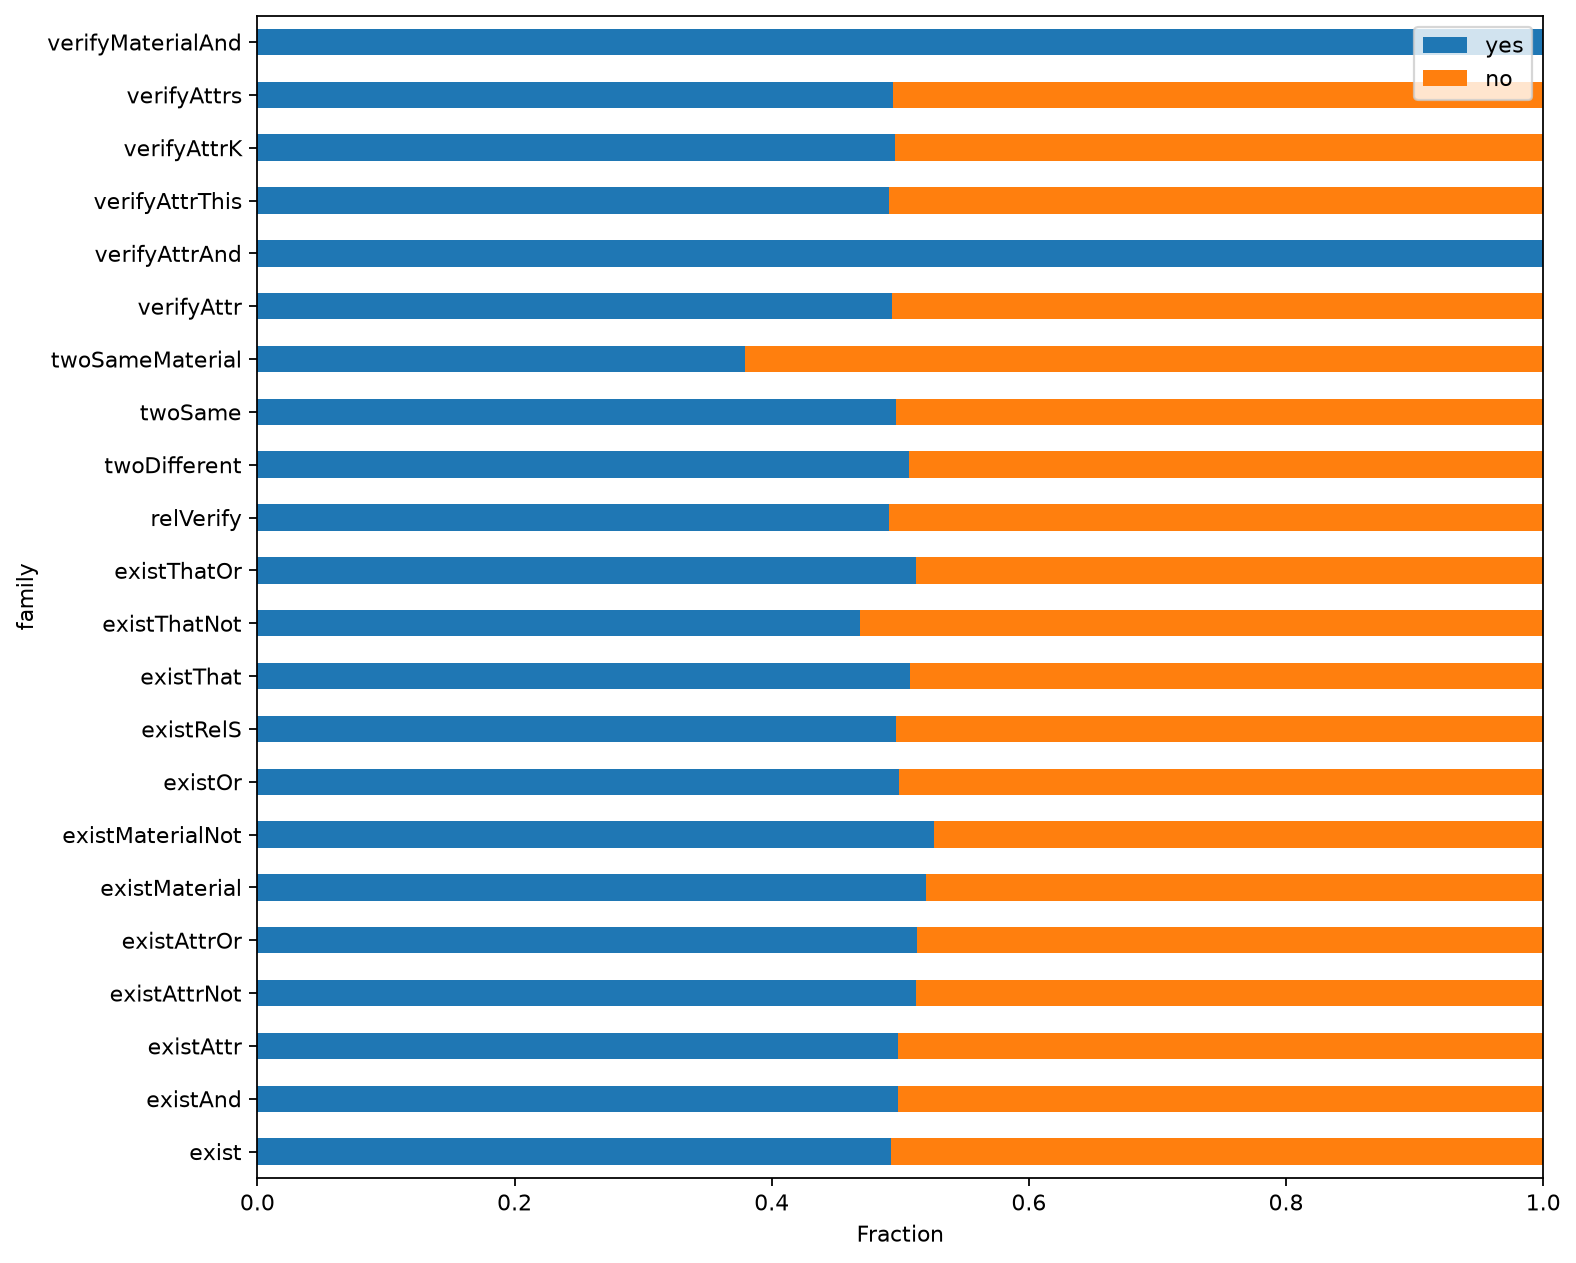

In [10]:
family_rows = variants[(variants['level'] == 'family') & (variants['split'] == 'train') & (variants['variant'] == 'unfiltered')].set_index('family')
family_rows = family_rows[family_rows['questions'] > 0]
print(family_rows[['task', 'questions', 'yes', 'no', 'flag']].to_string())
family_rows[['yes', 'no']].div(family_rows['questions'], axis=0).plot.barh(stacked=True, figsize=(10, 8))
plt.xlabel('Fraction'); plt.tight_layout(); plt.show()


## Tệp để duyệt

- `gqa_audit/config/task_rules.PROPOSED.yaml`
- `gqa_audit/config/op_family_map.PROPOSED.yaml`
- `gqa_audit/outputs/stage1/STAGE1_SUMMARY.md`
- `gqa_audit/outputs/stage1/relation_matches.csv`

**Dừng tại đây để người nghiên cứu duyệt.**
